In [18]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [19]:
# Load Dataset
df = pd.read_csv("datasets/sleep_health_unclean_dataset.csv", low_memory=False)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully
Dataset shape: (102000, 10)


,person_id,age,gender,occupation,bmi,country,sleep_duration_hrs,sleep_quality_score,rem_percentage,deep_sleep_percentage
0,97414,36.0,Male,Homemaker,NaN,Brazil,6.17,6.7,28.7,22.9
1,9139,33.0,Female,Retired,25.9,NaN,8.81,6.9,20.1,NaN
2,89079,30.0,Female,Student,27.4,India,4.69,2.6,21.7,19.5
3,42333,27.0,Male,Driver,27.9,USA,6.73,5.6,27.7,20.1
4,36833,23.0,Female,Freelancer,31.6,Brazil,7.68,8.1,21.9,24.8


In [20]:
# Understand the Dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print(df.columns.tolist())  # Column names

df.info() # Data types

# Numerical summary
df.describe(include="all")

# Missing values
print(df.isnull().sum())

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Number of rows: 102000
Number of columns: 10
['person_id', 'age', 'gender', 'occupation', 'bmi', 'country', 'sleep_duration_hrs', 'sleep_quality_score', 'rem_percentage', 'deep_sleep_percentage']
<class 'pandas.DataFrame'>
RangeIndex: 102000 entries, 0 to 101999
Data columns (total 10 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   person_id              102000 non-null  int64  
 1   age                    98378 non-null   str    
 2   gender                 98361 non-null   str    
 3   occupation             98359 non-null   str    
 4   bmi                    98349 non-null   str    
 5   country                98347 non-null   str    
 6   sleep_duration_hrs     98373 non-null   str    
 7   sleep_quality_score    98837 non-null   float64
 8   rem_percentage         99054 non-null   float64
 9   deep_sleep_percentage  98912 non-null   float64
dtypes: float64(3), int64(1), str(6)
memory usage: 7.8 MB
person_id 

In [21]:
# Remove Duplicate Records
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Shape after removing duplicates: (101471, 10)
Remaining duplicate rows: 0


In [22]:
# Clean Text Values

# Make a copy of the original data
df = df.copy()

# Clean extra spaces in text columns
text_cols = ["gender", "occupation", "country"]

for col in text_cols:
    df[col] = df[col].astype("string").str.strip()

# Replace invalid text markers with missing values
df = df.replace(
    ["?", "Unknown", "unknown", "invalid", "-999", ""],
    np.nan
)

print("Text cleaning completed")

Text cleaning completed


In [23]:
# Correct Inconsistent Categories

# Standardize gender values
df["gender"] = df["gender"].replace({
    "MALE": "Male",
    "male": "Male",
    "Malee": "Male",
    "  Male": "Male",
    "Male  ": "Male",
    "female": "Female",
    "Femle": "Female",
    "  Female": "Female"
})

# Standardize occupation values
df["occupation"] = df["occupation"].replace({
    "softwar engineer": "Software Engineer",
    "freelancer": "Freelancer",
    "  Driver": "Driver",
    "  Doctor": "Doctor",
    "Nurse  ": "Nurse",
    "Software Engineer  ": "Software Engineer"
})

# Standardize country values
df["country"] = df["country"].replace({
    "usa": "USA",
    "  USA": "USA",
    "USA  ": "USA",
    "japan": "Japan",
    "India  ": "India",
    "UK  ": "UK",
    " netherlands": "Netherlands"
})

print("Category cleaning completed")
print(df["gender"].value_counts(dropna=False))

Category cleaning completed
gender
Female    47877
Male      46916
<NA>       4908
Other      1770
Name: count, dtype: Int64


In [24]:
# Convert Numerical Columns

# Select numerical columns
numeric_cols = [
    "age",
    "bmi",
    "sleep_duration_hrs",
    "sleep_quality_score",
    "rem_percentage",
    "deep_sleep_percentage"
]

# Convert columns to numeric values
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[numeric_cols].dtypes)

age                      float64
bmi                      float64
sleep_duration_hrs       float64
sleep_quality_score      float64
rem_percentage           float64
deep_sleep_percentage    float64
dtype: object


In [25]:
# Handle Invalid Numerical Values

# Check valid age range
df.loc[(df["age"] < 0) | (df["age"] > 100), "age"] = np.nan

# Check valid BMI range
df.loc[(df["bmi"] < 10) | (df["bmi"] > 60), "bmi"] = np.nan

# Check valid sleep duration range
df.loc[
    (df["sleep_duration_hrs"] <= 0) |
    (df["sleep_duration_hrs"] > 24),
    "sleep_duration_hrs"
] = np.nan

# Check valid sleep quality score
df.loc[
    (df["sleep_quality_score"] < 1) |
    (df["sleep_quality_score"] > 10),
    "sleep_quality_score"
] = np.nan

# Check valid percentage ranges
for col in ["rem_percentage", "deep_sleep_percentage"]:
    df.loc[(df[col] < 0) | (df[col] > 100), col] = np.nan

print("Invalid numerical values handled")

Invalid numerical values handled


In [26]:
# Handle Missing Target Values

df = df.dropna(subset=["sleep_quality_score"])

print("Shape after removing missing target:", df.shape)
print(
    "Missing target values:",
    df["sleep_quality_score"].isnull().sum()
)

Shape after removing missing target: (98311, 10)
Missing target values: 0


In [27]:
# Separate Input and Target

# Select input features
X = df.drop(
    columns=["sleep_quality_score", "person_id"],
    errors="ignore"
)

# Select target variable
y = df["sleep_quality_score"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (98311, 8)
Target shape: (98311,)


In [28]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 78648
Testing records: 19663


In [29]:
# Fill Missing Input Values

# Identify numerical and categorical input columns
num_features = [
    "age",
    "bmi",
    "sleep_duration_hrs",
    "rem_percentage",
    "deep_sleep_percentage"
]

cat_features = ["gender", "occupation", "country"]

# Fill numerical missing values using training medians
for col in num_features:
    median_value = X_train[col].median()

    X_train[col] = X_train[col].fillna(median_value)
    X_test[col] = X_test[col].fillna(median_value)

# Fill categorical missing values using training modes
for col in cat_features:
    mode_value = X_train[col].mode()[0]

    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

print("Missing input values handled")

Missing input values handled


In [30]:
# Convert Categorical Data into Numbers

# Convert text categories into numerical columns
X_train = pd.get_dummies(
    X_train,
    columns=cat_features,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=cat_features,
    drop_first=True,
    dtype=int
)

# Keep the same columns in training and testing data
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (78648, 33)
Testing data shape: (19663, 33)


In [31]:
# Train Linear Regression Model

# Create the regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully")

Linear Regression model trained successfully


In [32]:
# Predict Output

# Predict sleep quality score
y_pred = model.predict(X_test)

# Display actual and predicted values
result = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": y_pred
})

display(result.head(10))

,Actual Score,Predicted Score
0,7.1,6.543055
1,5.5,5.164631
2,6.0,5.880210
3,4.9,4.755397
4,4.0,4.310241
5,6.7,5.301770
6,6.7,5.477355
7,6.2,5.338865
8,4.7,4.758428
9,4.6,3.695280


In [33]:
# Evaluate Regression Model

# Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test, y_pred)
print("MAE:", round(mae, 3))

# Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
print("MSE:", round(mse, 3))

# Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
print("RMSE:", round(rmse, 3))

# R² Score
r2 = r2_score(y_test, y_pred)
print("R2 Score:", round(r2, 3))


MAE: 0.869
MSE: 1.19
RMSE: 1.091
R2 Score: 0.475


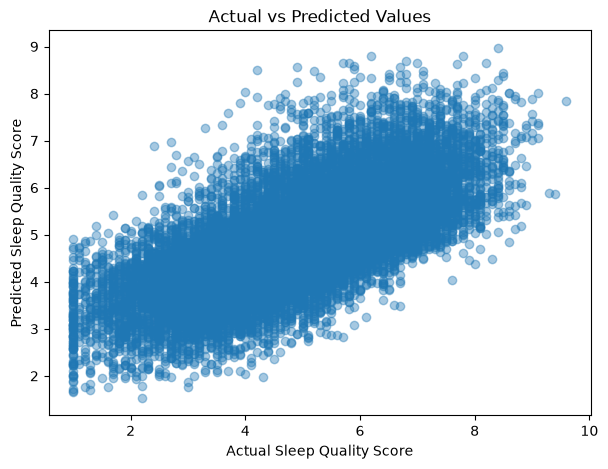

In [34]:
# Actual vs Predicted Graph

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual Sleep Quality Score")
plt.ylabel("Predicted Sleep Quality Score")
plt.title("Actual vs Predicted Values")

plt.show()

In [35]:
# Save Cleaned Dataset
df.to_csv("clean-datasets/sleep_health_cleaned.csv", index=False)

print("Cleaned dataset saved successfully")


Cleaned dataset saved successfully
